# TB1 – Klasifikasi Dua Kelas dengan Perceptron dan ADALINE
**Mata kuliah:** Jaringan Syaraf Tiruan (IT6053) – FTI UKDW  
**Kelompok:** XX (ganti dengan nomor kelompok) | **Anggota:** (isi nama/NIM)  
**Kasus:** Prediksi diabetes (Pima Indians Diabetes) dari 8 fitur klinis.

Alur notebook: (1) data & EDA → (2) split + standardisasi tanpa kebocoran → (3) implementasi NumPy → (4) perhitungan manual → (5) delapan pelatihan → (6) evaluasi & visualisasi → (7) analisis tambahan (keterpisahan linear, seleksi validasi, sensitivitas fitur) → (8) pembahasan.

Seluruh sel dapat dijalankan dari atas ke bawah (*Restart & Run All*). Data: `dataset.csv` di direktori yang sama.

In [1]:
import os, json, sys, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split   # hanya untuk membagi data (diizinkan)
from sklearn.linear_model import Perceptron as SkPerceptron  # hanya pembanding tambahan

SEED = 42
TEST_SIZE = 0.20
ETAS = [0.001, 0.01, 0.1]
EPOCHS = 50
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__)
RESULTS = {}   # dikumpulkan untuk laporan

Python 3.12.3 | numpy 2.4.4 | pandas 3.0.2 | matplotlib 3.10.8


## 1. Data dan EDA
Dataset: *Pima Indians Diabetes Database* (asal: NIDDK; Smith dkk., 1988; tersedia di UCI/Kaggle). Tiap baris = satu pasien perempuan keturunan Pima berusia ≥ 21 tahun. Target `Outcome`: 1 = diabetes (kelas **positif**, → +1), 0 = tidak diabetes (→ −1).

In [2]:
df = pd.read_csv("dataset.csv")
FEATURES = [c for c in df.columns if c != "Outcome"]
print("Jumlah observasi, kolom:", df.shape)
print("Missing value (NaN) per kolom:\n", df.isna().sum().to_dict())
print("Baris duplikat:", df.duplicated().sum())
print("Nilai 0 per fitur (0 tidak masuk akal untuk fitur klinis tertentu):")
print({c: int((df[c] == 0).sum()) for c in FEATURES})
dist = df["Outcome"].value_counts().sort_index()
print("\nDistribusi kelas:\n", dist.to_string(), "\nProporsi positif:", round(dist[1] / len(df), 4))
display(df.describe().T.round(3))

Jumlah observasi, kolom: (768, 9)
Missing value (NaN) per kolom:
 {'Pregnancies': 0, 'Glucose': 0, 'BloodPressure': 0, 'SkinThickness': 0, 'Insulin': 0, 'BMI': 0, 'DiabetesPedigreeFunction': 0, 'Age': 0, 'Outcome': 0}
Baris duplikat: 0
Nilai 0 per fitur (0 tidak masuk akal untuk fitur klinis tertentu):
{'Pregnancies': 111, 'Glucose': 0, 'BloodPressure': 0, 'SkinThickness': 0, 'Insulin': 0, 'BMI': 0, 'DiabetesPedigreeFunction': 0, 'Age': 0}

Distribusi kelas:
 Outcome
0    500
1    268 
Proporsi positif: 0.349


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845,3.370,0.000,1.000,3.000,6.000,17.00
Glucose,768.0,121.677,30.464,44.000,99.750,117.000,140.250,199.00
BloodPressure,768.0,72.389,12.106,24.000,64.000,72.000,80.000,122.00
SkinThickness,768.0,29.090,8.891,7.000,25.000,28.000,32.000,99.00
Insulin,768.0,141.754,89.101,14.000,102.500,102.500,169.500,846.00
BMI,768.0,32.435,6.880,18.200,27.500,32.050,36.600,67.10
DiabetesPedigreeFunction,768.0,0.472,0.331,0.078,0.244,0.372,0.626,2.42
Age,768.0,33.241,11.760,21.000,24.000,29.000,41.000,81.00
Outcome,768.0,0.349,0.477,0.000,0.000,0.000,1.000,1.00


### Temuan penting: data sudah diimputasi sebelum sampai ke kita
Tidak ada NaN dan tidak ada nilai 0 pada `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`. Di versi asli dataset ini, nilai 0 pada kolom-kolom tersebut berarti *tidak terukur*. Pada berkas yang kami terima, nilai itu sudah diganti. Sel berikut memeriksa pola penggantinya.

In [3]:
ins_counts = df.groupby("Outcome")["Insulin"].agg(lambda s: s.value_counts().head(1).to_dict())
skin_counts = df.groupby("Outcome")["SkinThickness"].agg(lambda s: s.value_counts().head(1).to_dict())
print("Nilai Insulin paling sering per kelas   :", ins_counts.to_dict())
print("Nilai SkinThickness paling sering/kelas :", skin_counts.to_dict())
n_ins = int(((df.Outcome == 0) & (df.Insulin == 102.5)).sum() + ((df.Outcome == 1) & (df.Insulin == 169.5)).sum())
n_skin = int(((df.Outcome == 0) & (df.SkinThickness == 27)).sum() + ((df.Outcome == 1) & (df.SkinThickness == 32)).sum())
print(f"\nBaris Insulin bernilai 'median kelas'      : {n_ins} dari {len(df)} ({n_ins/len(df):.1%})")
print(f"Baris SkinThickness bernilai 'median kelas': {n_skin} dari {len(df)} ({n_skin/len(df):.1%})")
RESULTS["imputed_insulin"] = n_ins; RESULTS["imputed_skin"] = n_skin

Nilai Insulin paling sering per kelas   : {0: {102.5: 236}, 1: {169.5: 138}}
Nilai SkinThickness paling sering/kelas : {0: {27: 155}, 1: {32: 102}}

Baris Insulin bernilai 'median kelas'      : 374 dari 768 (48.7%)
Baris SkinThickness bernilai 'median kelas': 257 dari 768 (33.5%)


**Interpretasi.** Satu nilai tunggal yang berbeda per kelas (Insulin 102,5 untuk kelas 0 dan 169,5 untuk kelas 1; SkinThickness 27 dan 32) muncul ratusan kali. Ini pola khas *imputasi median per kelas*, yaitu memakai label untuk mengisi fitur, dan dilakukan di seluruh data sebelum split. Akibatnya `Insulin` dan `SkinThickness` sebagian membawa informasi label (**kebocoran dari tahap pra-pengolahan yang tidak bisa kami batalkan**, karena nilai asli tidak tersedia). Dampaknya: akurasi bisa sedikit lebih optimistis. Kami mengukur dampaknya pada Bagian 7.3 dan mencantumkannya sebagai keterbatasan.

Untuk kepatuhan panduan: *imputasi* tidak diperlukan lagi (tidak ada NaN), sedangkan *standardisasi* dipelajari hanya dari data latih.

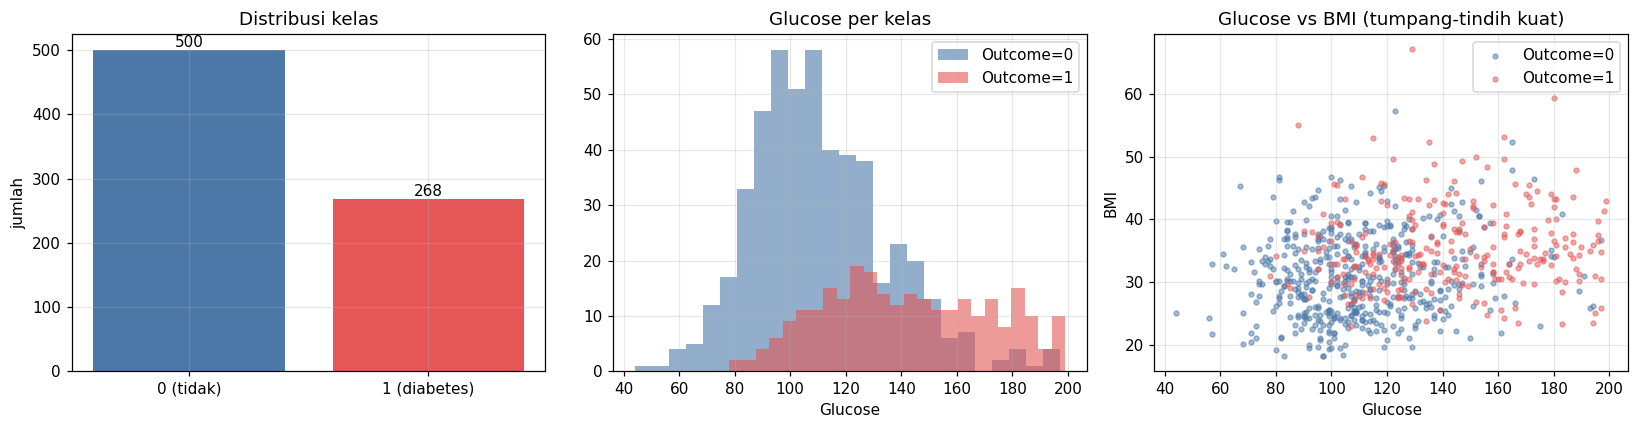

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].bar(["0 (tidak)", "1 (diabetes)"], dist.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(dist.values): ax[0].text(i, v + 5, str(v), ha="center")
ax[0].set_title("Distribusi kelas"); ax[0].set_ylabel("jumlah")
for k, c in [(0, "#4C78A8"), (1, "#E45756")]:
    ax[1].hist(df.loc[df.Outcome == k, "Glucose"], bins=25, alpha=.6, color=c, label=f"Outcome={k}")
    ax[2].scatter(df.loc[df.Outcome == k, "Glucose"], df.loc[df.Outcome == k, "BMI"], s=10, alpha=.5, color=c, label=f"Outcome={k}")
ax[1].set_title("Glucose per kelas"); ax[1].set_xlabel("Glucose"); ax[1].legend()
ax[2].set_title("Glucose vs BMI (tumpang-tindih kuat)"); ax[2].set_xlabel("Glucose"); ax[2].set_ylabel("BMI"); ax[2].legend()
plt.tight_layout(); plt.savefig("figures/eda.png", bbox_inches="tight"); plt.show()

## 2. Pembagian data dan standardisasi (tanpa kebocoran)
- Label: Outcome 1 → **+1 (positif)**, Outcome 0 → **−1**.
- Split 80:20, stratifikasi kelas, `random_state=42`. Indeks yang sama dipakai untuk semua model dan eksperimen.
- Standardisasi: μ dan σ dihitung **hanya dari data latih**, lalu diterapkan ke data uji.

In [5]:
X_all = df[FEATURES].to_numpy(dtype=float)
y_all = np.where(df["Outcome"].to_numpy() == 1, 1, -1)

idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
X_tr_raw, X_te_raw = X_all[idx_tr], X_all[idx_te]
y_tr, y_te = y_all[idx_tr], y_all[idx_te]

class Standardizer:
    # z = (x - mean) / std ; parameter dipelajari hanya dari data latih
    def fit(self, X):
        self.mu_ = X.mean(axis=0); self.sd_ = X.std(axis=0)
        self.sd_[self.sd_ == 0] = 1.0
        return self
    def transform(self, X): return (X - self.mu_) / self.sd_

sc = Standardizer().fit(X_tr_raw)
X_tr, X_te = sc.transform(X_tr_raw), sc.transform(X_te_raw)

print("Latih:", X_tr.shape, "| positif:", int((y_tr == 1).sum()), f"({(y_tr == 1).mean():.3f})")
print("Uji  :", X_te.shape, "| positif:", int((y_te == 1).sum()), f"({(y_te == 1).mean():.3f})")
print("Mean fitur latih terstandardisasi (≈0):", X_tr.mean(0).round(6))
print("Std  fitur latih terstandardisasi (≈1):", X_tr.std(0).round(6))
print("Mean fitur uji (tidak persis 0, wajar):", X_te.mean(0).round(3))

Latih: (614, 8) | positif: 214 (0.349)
Uji  : (154, 8) | positif: 54 (0.351)
Mean fitur latih terstandardisasi (≈0): [-0. -0.  0. -0.  0.  0.  0. -0.]
Std  fitur latih terstandardisasi (≈1): [1. 1. 1. 1. 1. 1. 1. 1.]
Mean fitur uji (tidak persis 0, wajar): [ 0.039 -0.006  0.099  0.04   0.197  0.005 -0.084 -0.053]


## 3. Implementasi model (NumPy mandiri)
**Neuron:** $z = w^\top x + b$, prediksi $\hat y=+1$ jika $z\ge 0$, selain itu $-1$. Inisialisasi $w=0,\ b=0$; urutan sampel tetap (urutan baris data latih).

**Perceptron (online, per sampel):** $\Delta=\eta(y-\hat y)$, $w\leftarrow w+\Delta x$, $b\leftarrow b+\Delta$. Dicatat: jumlah pembaruan (sampel salah) per epoch dan akurasi latih setelah tiap epoch.

**ADALINE (batch gradient descent, Delta Rule):** $e=y-z$ (keluaran *linear*, bukan keluaran ambang), $w\leftarrow w+\eta X^\top e/n$, $b\leftarrow b+\eta\,\overline{e}$. Loss $J=\frac{1}{2n}\sum (y_i-z_i)^2$ (MSE $=2J$). **Loss dicatat SEBELUM pembaruan pada epoch tersebut**; $J$ akhir dihitung ulang setelah pembaruan terakhir. Ambang hanya dipakai saat prediksi.

In [6]:
class Perceptron:
    def __init__(self, eta=0.01, epochs=50):
        self.eta, self.epochs = eta, epochs
    def net_input(self, X): return X @ self.w + self.b
    def predict(self, X):   return np.where(self.net_input(X) >= 0, 1, -1)
    def fit(self, X, y):
        n, d = X.shape
        self.w, self.b = np.zeros(d), 0.0
        self.updates_, self.train_acc_ = [], []
        for _ in range(self.epochs):
            n_upd = 0
            for xi, yi in zip(X, y):               # urutan tetap
                yhat = 1 if (xi @ self.w + self.b) >= 0 else -1
                delta = self.eta * (yi - yhat)
                self.w = self.w + delta * xi
                self.b = self.b + delta
                n_upd += int(yhat != yi)
            self.updates_.append(n_upd)
            self.train_acc_.append(float(np.mean(self.predict(X) == y)))
        return self

class Adaline:
    def __init__(self, eta=0.01, epochs=50):
        self.eta, self.epochs = eta, epochs
    def net_input(self, X): return X @ self.w + self.b
    def predict(self, X):   return np.where(self.net_input(X) >= 0, 1, -1)
    def loss(self, X, y):
        with np.errstate(all="ignore"):
            return float(np.sum((y - self.net_input(X)) ** 2) / (2 * len(y)))
    def fit(self, X, y):
        n, d = X.shape
        self.w, self.b = np.zeros(d), 0.0
        self.J_, self.train_acc_ = [], []
        self.diverged_epoch_ = None
        with np.errstate(all="ignore"):
            for ep in range(1, self.epochs + 1):
                z = X @ self.w + self.b
                e = y - z                              # error dari keluaran linear
                J = float(np.sum(e ** 2) / (2 * n))    # dicatat SEBELUM update
                if not np.isfinite(J):
                    self.diverged_epoch_ = ep; break   # hentikan jika inf/NaN
                self.J_.append(J)
                self.w = self.w + self.eta * (X.T @ e) / n
                self.b = self.b + self.eta * e.mean()
                self.train_acc_.append(float(np.mean(self.predict(X) == y)))
        self.J_final_ = self.loss(X, y)                # setelah update terakhir
        return self
print("Kelas Perceptron dan Adaline siap.")

Kelas Perceptron dan Adaline siap.


## 4. Perhitungan manual (dua langkah per model)
Agar bisa dihitung tangan, kami memakai **4 sampel latih pertama**, **dua fitur** (Glucose, BMI; terstandardisasi), $\eta=0{,}1$, $w=[0,0]$, $b=0$. Sel di bawah menghitung langkah demi langkah dengan rumus dasar (tanpa memanggil kelas), lalu **memverifikasi** hasilnya terhadap implementasi kelas.

In [7]:
cols = [FEATURES.index("Glucose"), FEATURES.index("BMI")]
Xm, ym = X_tr[:4][:, cols], y_tr[:4]
eta = 0.1
print("Data manual (Glucose_std, BMI_std, y):")
for xi, yi in zip(Xm, ym): print("  ", xi.round(4), int(yi))

# ---------- Perceptron: dua sampel ----------
print("\n=== PERCEPTRON (η=0,1) — dua sampel pertama ===")
w, b = np.zeros(2), 0.0
for t in range(2):
    x, y = Xm[t], ym[t]
    z = w @ x + b
    yhat = 1 if z >= 0 else -1
    delta = eta * (y - yhat)
    w_new, b_new = w + delta * x, b + delta
    print(f"Sampel {t+1}: x={x.round(4)}, y={y:+d}\n  z = w·x + b = {z:.4f} -> ŷ={yhat:+d}\n  Δ = η(y-ŷ) = {eta}*({y}-({yhat})) = {delta:.4f}")
    print(f"  w_baru = {w_new.round(4)}, b_baru = {b_new:.4f}")
    w, b = w_new, b_new
w_p_manual, b_p_manual = w.copy(), b
pc = Perceptron(eta=eta, epochs=1).fit(Xm[:2], ym[:2])
assert np.allclose(pc.w, w_p_manual) and np.isclose(pc.b, b_p_manual)
print("Bobot akhir (manual) =", w_p_manual.round(4), "bias =", round(b_p_manual, 4), "-> cocok dengan kelas ✔")

# ---------- ADALINE: dua iterasi batch ----------
print("\n=== ADALINE (η=0,1) — dua iterasi batch (n=4) ===")
w, b = np.zeros(2), 0.0
n = len(ym)
for it in range(2):
    z = Xm @ w + b
    e = ym - z
    J = np.sum(e ** 2) / (2 * n)
    gw = Xm.T @ e / n
    gb = e.mean()
    print(f"Iterasi {it+1}: z={z.round(4)}\n  e=y-z={e.round(4)}\n  J(sebelum update)={J:.4f}")
    print(f"  Xᵀe/n={gw.round(4)}, mean(e)={gb:.4f}")
    w, b = w + eta * gw, b + eta * gb
    print(f"  w_baru={w.round(4)}, b_baru={b:.4f}")
w_a_manual, b_a_manual = w.copy(), b
ad = Adaline(eta=eta, epochs=2).fit(Xm, ym)
assert np.allclose(ad.w, w_a_manual) and np.isclose(ad.b, b_a_manual)
print("Bobot akhir (manual) =", w_a_manual.round(4), "bias =", round(b_a_manual, 4), "-> cocok dengan kelas ✔")
RESULTS["manual"] = {"perc_w": w_p_manual.tolist(), "perc_b": float(b_p_manual),
                     "ada_w": w_a_manual.tolist(), "ada_b": float(b_a_manual)}

Data manual (Glucose_std, BMI_std, y):
   [-1.0569 -0.7662] -1
   [ 0.1429 -0.4144] -1
   [-0.557   0.3622] -1
   [ 0.8094 -0.3998] -1

=== PERCEPTRON (η=0,1) — dua sampel pertama ===
Sampel 1: x=[-1.0569 -0.7662], y=-1
  z = w·x + b = 0.0000 -> ŷ=+1
  Δ = η(y-ŷ) = 0.1*(-1-(1)) = -0.2000
  w_baru = [0.2114 0.1532], b_baru = -0.2000
Sampel 2: x=[ 0.1429 -0.4144], y=-1
  z = w·x + b = -0.2333 -> ŷ=-1
  Δ = η(y-ŷ) = 0.1*(-1-(-1)) = 0.0000
  w_baru = [0.2114 0.1532], b_baru = -0.2000
Bobot akhir (manual) = [0.2114 0.1532] bias = -0.2 -> cocok dengan kelas ✔

=== ADALINE (η=0,1) — dua iterasi batch (n=4) ===
Iterasi 1: z=[0. 0. 0. 0.]
  e=y-z=[-1. -1. -1. -1.]
  J(sebelum update)=0.5000
  Xᵀe/n=[0.1654 0.3045], mean(e)=-1.0000
  w_baru=[0.0165 0.0305], b_baru=-0.1000
Iterasi 2: z=[-0.1408 -0.1103 -0.0982 -0.0988]
  e=y-z=[-0.8592 -0.8897 -0.9018 -0.9012]
  J(sebelum update)=0.3944
  Xᵀe/n=[0.1385 0.2652], mean(e)=-0.8880
  w_baru=[0.0304 0.057 ], b_baru=-0.1888
Bobot akhir (manual) = [0.030

## 5. Delapan pelatihan
Konfigurasi ditetapkan **sebelum** melihat data uji: 2 model × η ∈ {0,001; 0,01; 0,1} × 50 epoch pada data terstandardisasi, ditambah 2 pelatihan **tanpa standardisasi** (η=0,01, 50 epoch). Pembagian data, inisialisasi nol, dan urutan sampel identik. Data uji hanya dipakai untuk pelaporan akhir tiap konfigurasi.

In [8]:
def confusion(y_true, y_pred):
    # baris = kelas sebenarnya, kolom = prediksi; urutan label [-1, +1]
    tn = int(np.sum((y_true == -1) & (y_pred == -1))); fp = int(np.sum((y_true == -1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == -1)));  tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    return np.array([[tn, fp], [fn, tp]])

def prf(cm):
    tn, fp, fn, tp = cm.ravel()
    p = tp / (tp + fp) if (tp + fp) else 0.0
    r = tp / (tp + fn) if (tp + fn) else 0.0
    f = 2 * p * r / (p + r) if (p + r) else 0.0
    return p, r, f

configs = []
for name, cls in [("Perceptron", Perceptron), ("ADALINE", Adaline)]:
    for eta in ETAS: configs.append((name, cls, eta, True))
    configs.append((name, cls, 0.01, False))

runs, rows = [], []
for name, cls, eta, std in configs:
    Xa, Xb = (X_tr, X_te) if std else (X_tr_raw, X_te_raw)
    m = cls(eta=eta, epochs=EPOCHS).fit(Xa, y_tr)
    with np.errstate(all="ignore"):
        ptr, pte = m.predict(Xa), m.predict(Xb)
    cm = confusion(y_te, pte); p, r, f = prf(cm)
    row = dict(model=name, eta=eta, epochs=EPOCHS, standardisasi="Ya" if std else "Tidak",
               acc_latih=float(np.mean(ptr == y_tr)), acc_uji=float(np.mean(pte == y_te)),
               precision=p, recall=r, f1=f)
    if name == "Perceptron":
        row["loss_akhir"] = f"{m.updates_[-1]} update (epoch 50)"
        row["err_latih_akhir"] = 1 - row["acc_latih"]
    else:
        row["loss_akhir"] = m.J_final_
        row["err_latih_akhir"] = 1 - row["acc_latih"]
        row["diverged_epoch"] = m.diverged_epoch_
    row["w"] = m.w.tolist(); row["b"] = float(m.b); row["cm"] = cm.tolist()
    runs.append((name, eta, std, m)); rows.append(row)

tab = pd.DataFrame(rows)
show = tab[["model", "eta", "epochs", "standardisasi", "acc_latih", "acc_uji", "precision", "recall", "f1", "loss_akhir", "err_latih_akhir"]].copy()
for c in ["acc_latih", "acc_uji", "precision", "recall", "f1", "err_latih_akhir"]: show[c] = show[c].round(4)
show["loss_akhir"] = show["loss_akhir"].map(lambda v: v if isinstance(v, str) else float(f"{v:.6g}"))
display(show)
print("Divergensi ADALINE (epoch kejadian, None = tidak terjadi):",
      {f"eta={r['eta']}, std={r['standardisasi']}": r.get('diverged_epoch') for r in rows if r['model']=='ADALINE'})
RESULTS["table"] = [{k: v for k, v in r.items()} for r in rows]

,model,eta,epochs,standardisasi,acc_latih,acc_uji,precision,recall,f1,loss_akhir,err_latih_akhir
0,Perceptron,0.001,50,Ya,0.6889,0.7013,0.5769,0.5556,0.5660,176 update (epoch 50),0.3111
1,Perceptron,0.010,50,Ya,0.6889,0.7013,0.5769,0.5556,0.5660,176 update (epoch 50),0.3111
2,Perceptron,0.100,50,Ya,0.6889,0.7013,0.5769,0.5556,0.5660,176 update (epoch 50),0.3111
3,Perceptron,0.010,50,Tidak,0.6612,0.6299,0.3636,0.0741,0.1231,213 update (epoch 50),0.3388
4,ADALINE,0.001,50,Ya,0.7915,0.7338,0.6032,0.7037,0.6496,0.462518,0.2085
5,ADALINE,0.010,50,Ya,0.7932,0.7532,0.6333,0.7037,0.6667,0.327633,0.2068
6,ADALINE,0.100,50,Ya,0.7997,0.7273,0.6304,0.5370,0.5800,0.289977,0.2003
7,ADALINE,0.010,50,Tidak,0.3485,0.3506,0.3506,1.0000,0.5192,1305710000000000010370457106556881365452612142...,0.6515


Divergensi ADALINE (epoch kejadian, None = tidak terjadi): {'eta=0.001, std=Ya': None, 'eta=0.01, std=Ya': None, 'eta=0.1, std=Ya': None, 'eta=0.01, std=Tidak': None}


### 5.1 Kondisi epoch ke-10, ke-30, dan ke-50 (dari riwayat pelatihan)
Perceptron: jumlah pembaruan pada epoch itu dan akurasi latih setelah epoch itu. ADALINE: $J$ (sebelum pembaruan epoch itu) dan akurasi latih setelah epoch itu.

In [9]:
hist_rows = []
for name, eta, std, m in runs:
    for ep in (10, 30, 50):
        if name == "Perceptron":
            hist_rows.append(dict(model=name, eta=eta, std="Ya" if std else "Tidak", epoch=ep,
                                  metrik="update salah", nilai=m.updates_[ep-1], acc_latih=round(m.train_acc_[ep-1], 4)))
        else:
            if ep <= len(m.J_):
                hist_rows.append(dict(model=name, eta=eta, std="Ya" if std else "Tidak", epoch=ep,
                                      metrik="J", nilai=float(f"{m.J_[ep-1]:.6g}"), acc_latih=round(m.train_acc_[ep-1], 4)))
            else:
                hist_rows.append(dict(model=name, eta=eta, std="Ya" if std else "Tidak", epoch=ep, metrik="J", nilai="diverge", acc_latih=None))
H = pd.DataFrame(hist_rows)
display(H.pivot_table(index=["model", "eta", "std"], columns="epoch", values=["nilai", "acc_latih"], aggfunc="first"))
RESULTS["hist"] = hist_rows

acc_latih                         nilai                 \
epoch                         10      30      50            10             30   
model      eta   std                                                            
ADALINE    0.001 Ya       0.7899  0.7915  0.7915  4.926210e-01   4.772500e-01   
           0.010 Tidak    0.3485  0.3485  0.3485  1.043270e+46  7.855990e+152   
                 Ya       0.7932  0.7899  0.7932  4.374680e-01   3.619330e-01   
           0.100 Ya       0.7948  0.7980  0.7997  3.025680e-01   2.905580e-01   
Perceptron 0.001 Ya       0.7818  0.7915  0.6889  1.700000e+02   1.670000e+02   
           0.010 Tidak    0.6612  0.6564  0.6612  2.130000e+02   2.190000e+02   
                 Ya       0.7818  0.7915  0.6889  1.700000e+02   1.670000e+02   
           0.100 Ya       0.7818  0.7915  0.6889  1.700000e+02   1.670000e+02   

                                       
epoch                              50  
model      eta   std                   
ADALINE    0.001 Ya      4.631890e-01  
           0.010 Tidak  5.915700e+259  
                 Ya      3.287190e-01  
           0.100 Ya      2.899860e-01  
Perceptron 0.001 Ya      1.760000e+02  
           0.010 Tidak   2.130000e+02  
                 Ya      1.760000e+02  
           0.100 Ya      1.760000e+02

## 6. Evaluasi dan visualisasi

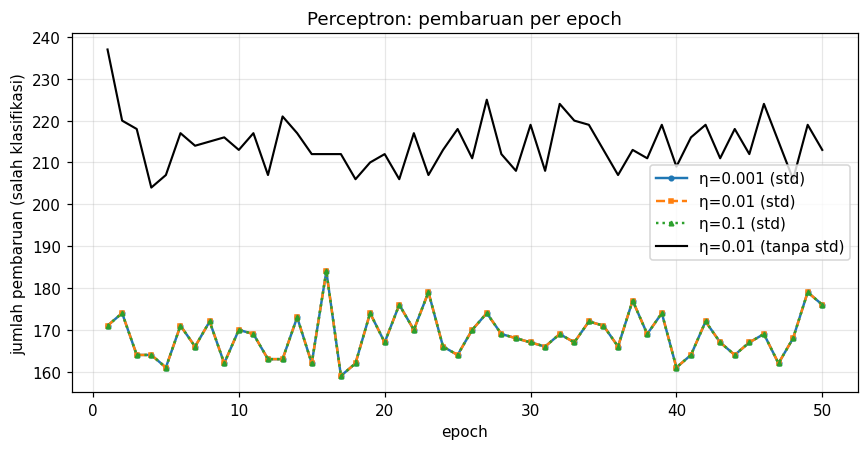

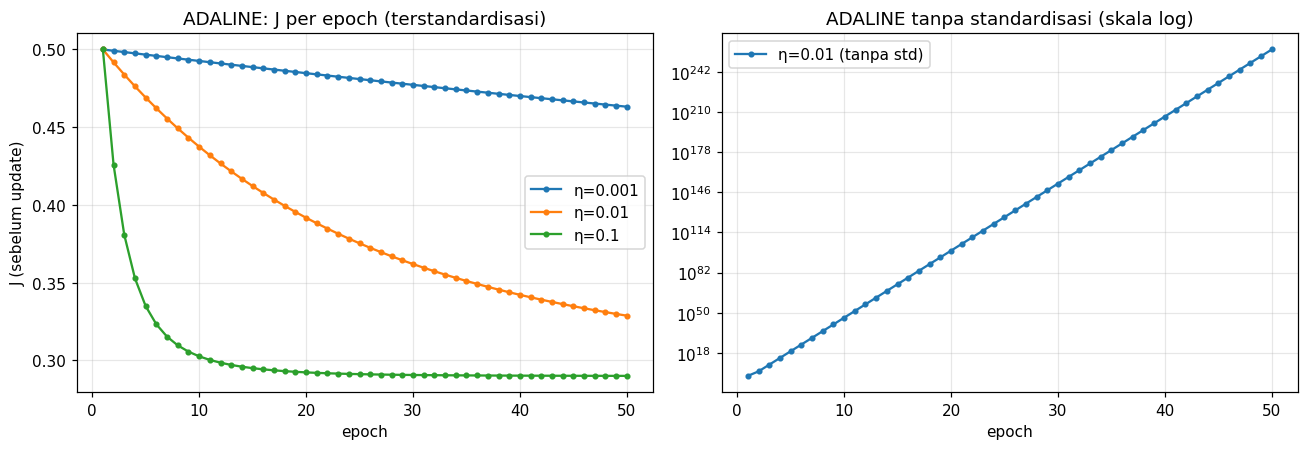

ADALINE tanpa standardisasi: J epoch1=0.5, epoch50=5.916e+259, J_akhir=1.306e+265, diverge_epoch=None


In [10]:
# Kurva Perceptron
fig, ax = plt.subplots(figsize=(8, 4.2))
styles = {0.001: ("o", "-"), 0.01: ("s", "--"), 0.1: ("^", ":")}
for name, eta, std, m in runs:
    if name != "Perceptron": continue
    if std:
        ax.plot(range(1, EPOCHS + 1), m.updates_, ls=styles[eta][1], marker=styles[eta][0], ms=3, lw=1.6, label=f"η={eta} (std)")
    else:
        ax.plot(range(1, EPOCHS + 1), m.updates_, color="k", lw=1.4, label=f"η={eta} (tanpa std)")
ax.set_xlabel("epoch"); ax.set_ylabel("jumlah pembaruan (salah klasifikasi)")
ax.set_title("Perceptron: pembaruan per epoch"); ax.legend(); plt.tight_layout()
plt.savefig("figures/curve_perceptron.png", bbox_inches="tight"); plt.show()

# Kurva ADALINE
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for name, eta, std, m in runs:
    if name != "ADALINE": continue
    a = ax[0] if std else ax[1]
    a.plot(range(1, len(m.J_) + 1), m.J_, marker="o", ms=3, label=f"η={eta}" + ("" if std else " (tanpa std)"))
ax[0].set_title("ADALINE: J per epoch (terstandardisasi)"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("J (sebelum update)")
ax[1].set_title("ADALINE tanpa standardisasi (skala log)"); ax[1].set_yscale("log"); ax[1].set_xlabel("epoch")
for a in ax: a.legend()
plt.tight_layout(); plt.savefig("figures/curve_adaline.png", bbox_inches="tight"); plt.show()
for name, eta, std, m in runs:
    if name == "ADALINE" and not std:
        print(f"ADALINE tanpa standardisasi: J epoch1={m.J_[0]:.4g}, epoch{len(m.J_)}={m.J_[-1]:.4g}, J_akhir={m.J_final_:.4g}, diverge_epoch={m.diverged_epoch_}")

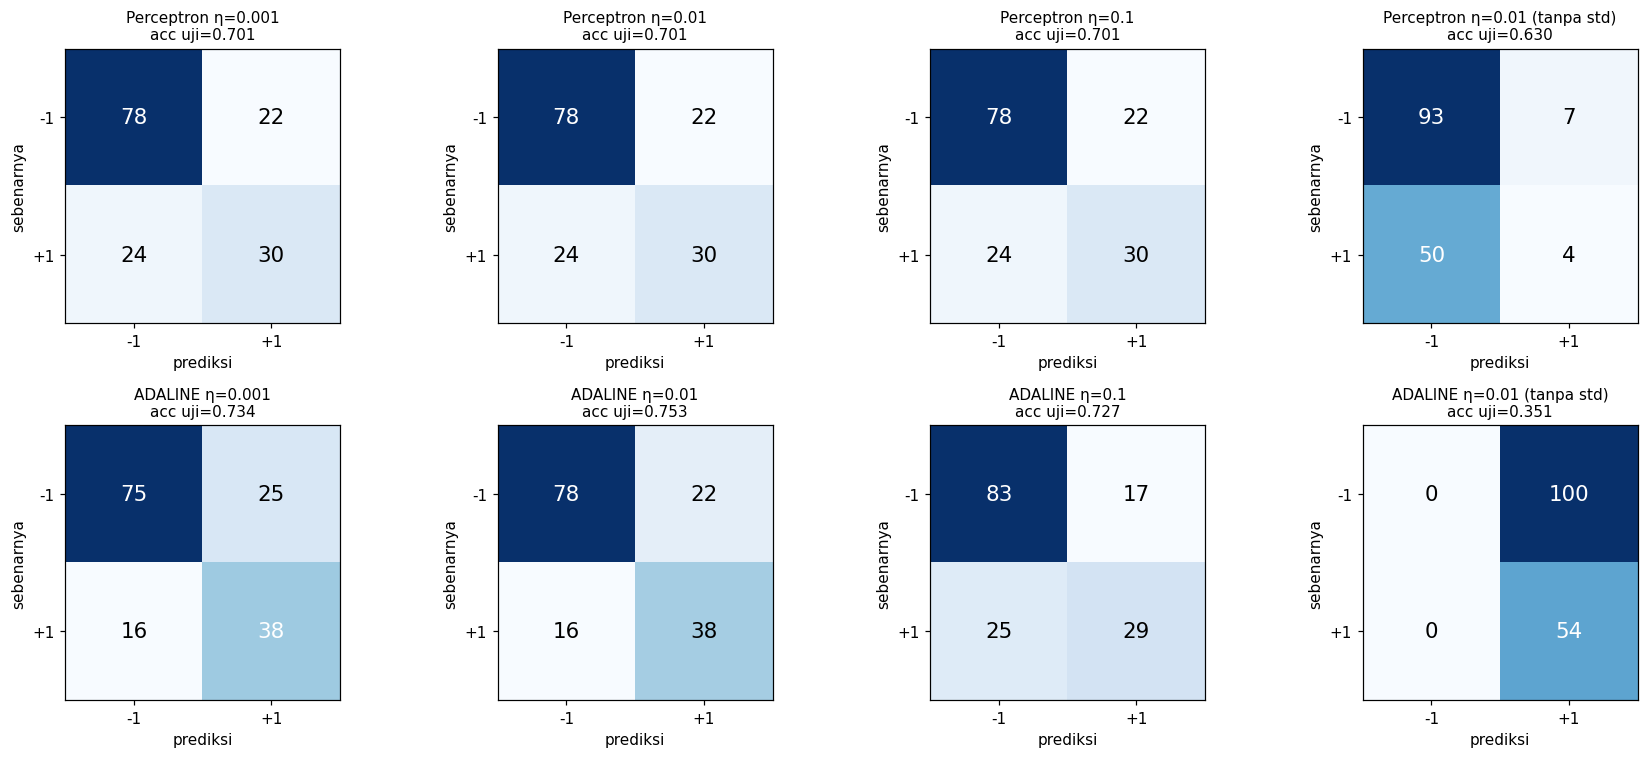

Urutan label: [-1 (tidak diabetes), +1 (diabetes, kelas positif)]; [[TN, FP], [FN, TP]]


In [11]:
# Confusion matrix data uji (baris = sebenarnya, kolom = prediksi; urutan [-1, +1])
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, (name, eta, std, m), r in zip(axs.ravel(), runs, rows):
    cm = np.array(r["cm"])
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                                   color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["-1", "+1"]); ax.set_yticklabels(["-1", "+1"])
    ax.set_xlabel("prediksi"); ax.set_ylabel("sebenarnya")
    ax.set_title(f"{name} η={eta}{'' if std else ' (tanpa std)'}\nacc uji={r['acc_uji']:.3f}", fontsize=10)
plt.tight_layout(); plt.savefig("figures/confusion.png", bbox_inches="tight"); plt.show()
print("Urutan label: [-1 (tidak diabetes), +1 (diabetes, kelas positif)]; [[TN, FP], [FN, TP]]")

In [12]:
# Bobot & bias akhir
wt = []
for name, eta, std, m in runs:
    wt.append({"model": name, "eta": eta, "std": "Ya" if std else "Tidak",
               **{f: float(f"{v:.5g}") for f, v in zip(FEATURES, m.w)}, "bias": float(f"{m.b:.5g}")})
WT = pd.DataFrame(wt); display(WT)
RESULTS["features"] = FEATURES

,model,eta,std,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,bias
0,Perceptron,0.001,Ya,5.217300e-03,-4.381200e-04,1.188200e-03,-6.602400e-04,4.706000e-03,3.504200e-03,-3.861100e-03,-3.089900e-03,-4.000000e-03
1,Perceptron,0.010,Ya,5.217300e-02,-4.381200e-03,1.188200e-02,-6.602400e-03,4.706000e-02,3.504200e-02,-3.861100e-02,-3.089900e-02,-4.000000e-02
2,Perceptron,0.100,Ya,5.217300e-01,-4.381200e-02,1.188200e-01,-6.602400e-02,4.706000e-01,3.504200e-01,-3.861100e-01,-3.089900e-01,-4.000000e-01
3,Perceptron,0.010,Tidak,1.404000e+01,-1.400000e+00,-2.298000e+01,2.280000e+00,4.840000e+00,5.392000e+00,2.580000e+00,-2.660000e+00,-1.574000e+01
4,ADALINE,0.001,Ya,9.341800e-03,2.339600e-02,8.390600e-03,1.383000e-02,1.916300e-02,1.491900e-02,7.418600e-03,1.070000e-02,-1.478100e-02
5,ADALINE,0.010,Ya,5.780100e-02,1.574300e-01,4.228500e-02,7.915700e-02,1.213200e-01,9.145800e-02,4.518400e-02,5.982200e-02,-1.196600e-01
6,ADALINE,0.100,Ya,1.061300e-01,3.165900e-01,8.861900e-03,6.812300e-02,1.572500e-01,1.472300e-01,5.413700e-02,4.086600e-02,-3.013700e-01
7,ADALINE,0.010,Tidak,4.085000e+128,1.322600e+130,7.491200e+129,3.079700e+129,1.702800e+130,3.401700e+129,5.141100e+127,3.523300e+129,1.025500e+128


In [13]:
# Pengaruh η pada Perceptron berinisialisasi nol: bobot hanya diskalakan
P = {eta: m for name, eta, std, m in runs if name == "Perceptron" and std}
print("w/η untuk tiap η (jika identik, η hanya menskalakan bobot):")
for eta, m in P.items(): print(f"  η={eta}: w/η =", (m.w / eta).round(3), "| b/η =", round(m.b / eta, 3))
same_pred = all(np.array_equal(P[0.001].predict(X_te), P[e].predict(X_te)) for e in (0.01, 0.1))
same_upd = P[0.001].updates_ == P[0.01].updates_ == P[0.1].updates_
print("Prediksi uji identik untuk 3 nilai η:", same_pred, "| riwayat update identik:", same_upd)
RESULTS["perc_eta_scaling"] = {"same_pred": bool(same_pred), "same_updates": bool(same_upd),
                               "w_over_eta": (P[0.01].w / 0.01).tolist(), "b_over_eta": float(P[0.01].b / 0.01)}

w/η untuk tiap η (jika identik, η hanya menskalakan bobot):
  η=0.001: w/η = [ 5.217 -0.438  1.188 -0.66   4.706  3.504 -3.861 -3.09 ] | b/η = -4.0
  η=0.01: w/η = [ 5.217 -0.438  1.188 -0.66   4.706  3.504 -3.861 -3.09 ] | b/η = -4.0
  η=0.1: w/η = [ 5.217 -0.438  1.188 -0.66   4.706  3.504 -3.861 -3.09 ] | b/η = -4.0
Prediksi uji identik untuk 3 nilai η: True | riwayat update identik: True


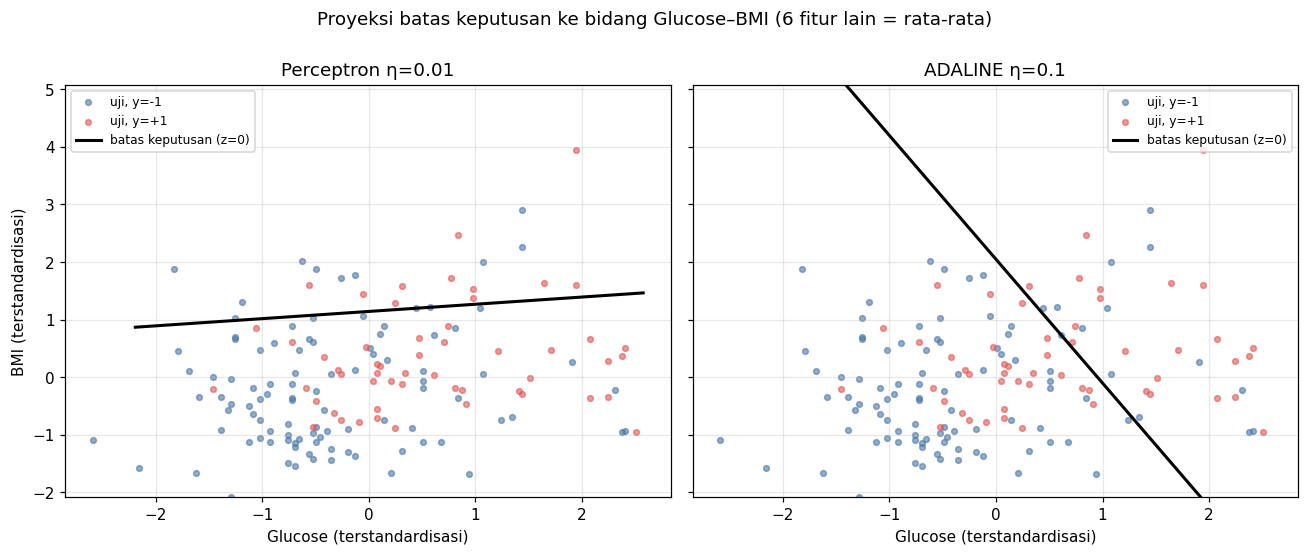

In [14]:
# Decision boundary: proyeksi 2 fitur (Glucose, BMI) dari model 8 fitur.
# Enam fitur lain ditahan pada rata-rata data latih (= 0 pada ruang terstandardisasi).
gi, bi = FEATURES.index("Glucose"), FEATURES.index("BMI")
sel = [("Perceptron", 0.01), ("ADALINE", 0.1)]
fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (nm, et) in zip(axs, sel):
    m = [mm for n_, e_, s_, mm in runs if n_ == nm and e_ == et and s_][0]
    for k, c in [(-1, "#4C78A8"), (1, "#E45756")]:
        ax.scatter(X_te[y_te == k, gi], X_te[y_te == k, bi], s=14, alpha=.6, color=c, label=f"uji, y={k:+d}")
    xs = np.linspace(X_tr[:, gi].min(), X_tr[:, gi].max(), 100)
    # w_g*g + w_b*bmi + b = 0  ->  bmi = -(w_g*g + b)/w_b
    ax.plot(xs, -(m.w[gi] * xs + m.b) / m.w[bi], "k-", lw=2, label="batas keputusan (z=0)")
    ax.set_ylim(X_tr[:, bi].min(), X_tr[:, bi].max())
    ax.set_xlabel("Glucose (terstandardisasi)"); ax.set_title(f"{nm} η={et}")
    ax.legend(fontsize=8)
axs[0].set_ylabel("BMI (terstandardisasi)")
plt.suptitle("Proyeksi batas keputusan ke bidang Glucose–BMI (6 fitur lain = rata-rata)", y=1.0)
plt.tight_layout(); plt.savefig("figures/decision_boundary.png", bbox_inches="tight"); plt.show()

## 7. Analisis tambahan
### 7.1 Indikasi keterpisahan linear
Pelatihan Perceptron diperpanjang menjadi 1000 epoch (η=0,01, terstandardisasi) hanya sebagai **diagnostik pada data latih**. Jika data terpisah linear, jumlah pembaruan akan mencapai 0 (teorema konvergensi Perceptron). Lalu ADALINE dibandingkan dengan solusi kuadrat-terkecil tertutup (`np.linalg.lstsq`) untuk memeriksa bahwa implementasinya konvergen ke minimum $J$ yang benar.

Perceptron 1000 epoch: update min=152 (epoch 119), update rata-rata epoch 951-1000=170.1
Akurasi latih terbaik selama 1000 epoch = 0.8290; epoch dengan 0 update: 0

J minimum tertutup (lstsq) = 0.289887 | J ADALINE η=0,1 setelah 2000 epoch = 0.289887
Selisih maks bobot ADALINE vs lstsq: 7.771561172376096e-16
Akurasi latih/uji dari solusi lstsq: 0.798 0.7273


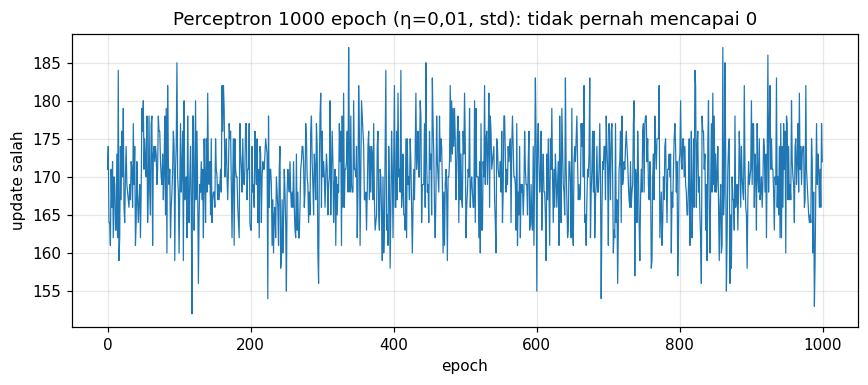

In [15]:
long = Perceptron(eta=0.01, epochs=1000).fit(X_tr, y_tr)
upd = np.array(long.updates_)
print(f"Perceptron 1000 epoch: update min={upd.min()} (epoch {upd.argmin()+1}), update rata-rata epoch 951-1000={upd[-50:].mean():.1f}")
print(f"Akurasi latih terbaik selama 1000 epoch = {max(long.train_acc_):.4f}; epoch dengan 0 update: {int((upd==0).sum())}")

Xb_tr = np.hstack([X_tr, np.ones((len(X_tr), 1))])
w_ls, *_ = np.linalg.lstsq(Xb_tr, y_tr.astype(float), rcond=None)
J_ls = np.sum((y_tr - Xb_tr @ w_ls) ** 2) / (2 * len(y_tr))
ad_long = Adaline(eta=0.1, epochs=2000).fit(X_tr, y_tr)
print(f"\nJ minimum tertutup (lstsq) = {J_ls:.6f} | J ADALINE η=0,1 setelah 2000 epoch = {ad_long.J_final_:.6f}")
print("Selisih maks bobot ADALINE vs lstsq:", float(np.max(np.abs(np.r_[ad_long.w, ad_long.b] - w_ls))))
print("Akurasi latih/uji dari solusi lstsq:",
      round(float(np.mean(np.where(Xb_tr @ w_ls >= 0, 1, -1) == y_tr)), 4),
      round(float(np.mean(np.where(np.hstack([X_te, np.ones((len(X_te),1))]) @ w_ls >= 0, 1, -1) == y_te)), 4))
RESULTS["longrun"] = {"min_updates": int(upd.min()), "argmin": int(upd.argmin() + 1), "mean_last50": float(upd[-50:].mean()),
                      "best_train_acc": float(max(long.train_acc_)), "zero_epochs": int((upd == 0).sum()),
                      "J_ls": float(J_ls), "J_ada2000": float(ad_long.J_final_)}
fig, ax = plt.subplots(figsize=(8, 3.6)); ax.plot(upd, lw=.8)
ax.set_xlabel("epoch"); ax.set_ylabel("update salah"); ax.set_title("Perceptron 1000 epoch (η=0,01, std): tidak pernah mencapai 0")
plt.tight_layout(); plt.savefig("figures/longrun.png", bbox_inches="tight"); plt.show()

### 7.2 Seleksi η dengan data validasi (dari data latih saja)
Jika harus memilih satu η per model, seleksi dilakukan pada validasi 20% dari **data latih** (standardisasi dipelajari ulang dari sub-latih). Data uji tidak disentuh.

In [16]:
i_sub, i_val = train_test_split(np.arange(len(y_tr)), test_size=0.2, stratify=y_tr, random_state=SEED)
sc2 = Standardizer().fit(X_tr_raw[i_sub])
Xs, Xv = sc2.transform(X_tr_raw[i_sub]), sc2.transform(X_tr_raw[i_val])
ys, yv = y_tr[i_sub], y_tr[i_val]
val = []
for name, cls in [("Perceptron", Perceptron), ("ADALINE", Adaline)]:
    for eta in ETAS:
        m = cls(eta=eta, epochs=EPOCHS).fit(Xs, ys)
        val.append(dict(model=name, eta=eta, acc_validasi=round(float(np.mean(m.predict(Xv) == yv)), 4)))
V = pd.DataFrame(val); display(V)
sel_eta = {n: float(V[V.model == n].sort_values(["acc_validasi", "eta"], ascending=[False, True]).iloc[0].eta) for n in ["Perceptron", "ADALINE"]}
print("η terpilih (akurasi validasi tertinggi; seri -> η terkecil):", sel_eta)
RESULTS["val"] = val; RESULTS["sel_eta"] = sel_eta

,model,eta,acc_validasi
0,Perceptron,0.001,0.6911
1,Perceptron,0.010,0.6911
2,Perceptron,0.100,0.6911
3,ADALINE,0.001,0.8618
4,ADALINE,0.010,0.8699
5,ADALINE,0.100,0.8293


η terpilih (akurasi validasi tertinggi; seri -> η terkecil): {'Perceptron': 0.001, 'ADALINE': 0.01}


### 7.3 Sensitivitas terhadap fitur hasil imputasi berlabel
`Insulin` dan `SkinThickness` adalah dua kolom yang paling banyak terimputasi dengan median per kelas (Bagian 1). Kami melatih ulang kedua model (η=0,01 untuk Perceptron, η=0,1 untuk ADALINE; terstandardisasi; 50 epoch; split yang sama) **tanpa** kedua kolom ini sebagai uji sensitivitas. Ini analisis tambahan, bukan pengganti hasil utama.

In [17]:
keep = [i for i, f in enumerate(FEATURES) if f not in ("Insulin", "SkinThickness")]
sc3 = Standardizer().fit(X_tr_raw[:, keep])
X3tr, X3te = sc3.transform(X_tr_raw[:, keep]), sc3.transform(X_te_raw[:, keep])
sens = []
for name, cls, eta in [("Perceptron", Perceptron, 0.01), ("ADALINE", Adaline, 0.1)]:
    m = cls(eta=eta, epochs=EPOCHS).fit(X3tr, y_tr)
    full = [r for r in rows if r["model"] == name and r["eta"] == eta and r["standardisasi"] == "Ya"][0]
    sens.append(dict(model=name, eta=eta, acc_uji_8fitur=round(full["acc_uji"], 4),
                     acc_uji_6fitur=round(float(np.mean(m.predict(X3te) == y_te)), 4),
                     acc_latih_6fitur=round(float(np.mean(m.predict(X3tr) == y_tr)), 4)))
S = pd.DataFrame(sens); display(S); RESULTS["sens"] = sens

,model,eta,acc_uji_8fitur,acc_uji_6fitur,acc_latih_6fitur
0,Perceptron,0.01,0.7013,0.6948,0.6710
1,ADALINE,0.10,0.7273,0.6948,0.7899


### 7.4 Apakah akurasi sama berarti proses belajar sama? + pembanding siap-pakai
Membandingkan Perceptron (η=0,01) dan ADALINE (η=0,1) pada data terstandardisasi, plus pembanding `sklearn.linear_model.Perceptron` (hanya verifikasi tambahan, bukan pengganti implementasi mandiri).

In [18]:
mp = [m for n_, e_, s_, m in runs if n_ == "Perceptron" and e_ == 0.01 and s_][0]
ma = [m for n_, e_, s_, m in runs if n_ == "ADALINE" and e_ == 0.1 and s_][0]
agree_te = float(np.mean(mp.predict(X_te) == ma.predict(X_te)))
agree_tr = float(np.mean(mp.predict(X_tr) == ma.predict(X_tr)))
cos = float(mp.w @ ma.w / (np.linalg.norm(mp.w) * np.linalg.norm(ma.w)))
print(f"Kesepakatan prediksi Perceptron vs ADALINE: latih={agree_tr:.4f}, uji={agree_te:.4f}")
print(f"Kosinus antar vektor bobot = {cos:.4f}")
print("Bobot Perceptron/||.||:", (mp.w / np.linalg.norm(mp.w)).round(3))
print("Bobot ADALINE/||.||   :", (ma.w / np.linalg.norm(ma.w)).round(3))

sk = SkPerceptron(eta0=0.01, max_iter=50, tol=None, shuffle=False, penalty=None, fit_intercept=True, random_state=SEED).fit(X_tr, y_tr)
print(f"\nsklearn Perceptron (pembanding): acc latih={sk.score(X_tr, y_tr):.4f}, acc uji={sk.score(X_te, y_te):.4f}; "
      f"kesepakatan prediksi uji dengan implementasi kita={np.mean(sk.predict(X_te) == mp.predict(X_te)):.4f}")
RESULTS["compare"] = {"agree_te": agree_te, "agree_tr": agree_tr, "cos": cos,
                      "sk_train": float(sk.score(X_tr, y_tr)), "sk_test": float(sk.score(X_te, y_te)),
                      "sk_agree": float(np.mean(sk.predict(X_te) == mp.predict(X_te)))}

Kesepakatan prediksi Perceptron vs ADALINE: latih=0.7557, uji=0.7792
Kosinus antar vektor bobot = 0.3389
Bobot Perceptron/||.||: [ 0.556 -0.047  0.127 -0.07   0.501  0.373 -0.411 -0.329]
Bobot ADALINE/||.||   : [0.26  0.774 0.022 0.167 0.385 0.36  0.132 0.1  ]

sklearn Perceptron (pembanding): acc latih=0.6889, acc uji=0.7013; kesepakatan prediksi uji dengan implementasi kita=1.0000


### 7.5 Mengapa ADALINE tanpa standardisasi meledak? Batas kestabilan η
Pada gradient descent untuk kuadrat-terkecil, $J$ turun hanya jika $\eta<2/\lambda_{\max}$, dengan $\lambda_{\max}$ nilai eigen terbesar dari $\tfrac1n\tilde X^\top\tilde X$ ($\tilde X$ = fitur + kolom bias).

In [19]:
def lam_max(X):
    Xt = np.hstack([X, np.ones((len(X), 1))])
    return float(np.linalg.eigvalsh(Xt.T @ Xt / len(Xt)).max())
lm_std, lm_raw = lam_max(X_tr), lam_max(X_tr_raw)
print(f"Terstandardisasi: λmax={lm_std:.3f} -> η stabil < {2/lm_std:.4f}")
print(f"Tanpa standardisasi: λmax={lm_raw:.1f} -> η stabil < {2/lm_raw:.6f}  (η=0,01 jauh di atas batas)")
RESULTS["stability"] = {"lam_std": lm_std, "lam_raw": lm_raw, "eta_max_std": 2/lm_std, "eta_max_raw": 2/lm_raw}

Terstandardisasi: λmax=2.464 -> η stabil < 0.8116
Tanpa standardisasi: λmax=47080.8 -> η stabil < 0.000042  (η=0,01 jauh di atas batas)


## 8. Pembahasan, keterbatasan, dan kesimpulan
Angka di bawah berasal dari keluaran sel di atas (seed 42, split 80:20; 614 latih, 154 uji; uji berisi 54 positif).

**1. Apakah data terpisah linear? Tidak ada indikasi bahwa data terpisah linear.**
- Pola data: pada bidang Glucose–BMI kedua kelas tumpang-tindih kuat (Bagian 1).
- Perilaku pelatihan: pada Perceptron yang dilatih 1000 epoch, pembaruan per epoch tidak pernah mencapai 0 (minimum 152 pada epoch 119; rata-rata 170,1 pada epoch 951–1000). Pada data yang terpisah linear, teorema konvergensi Perceptron menjamin pembaruan akan berhenti. Ini indikasi kuat, bukan bukti formal, karena jumlah epoch terbatas.
- Batas atas model linear: akurasi latih terbaik Perceptron selama 1000 epoch 0,829; solusi kuadrat-terkecil tertutup hanya 0,798 pada data latih. ADALINE konvergen ke $J_{\min}=0{,}2899$, jauh dari 0.

**2. Perbedaan error.** Perceptron memakai error diskret $y-\hat y\in\{-2,0,+2\}$ dari keluaran ambang: bobot hanya berubah ketika sampel salah, tanpa fungsi objektif yang diturunkan. ADALINE memakai error kontinu $y-z$ dari keluaran linear; semua sampel ikut menyumbang gradien $J$ pada setiap iterasi, termasuk sampel yang sudah benar tetapi belum mencapai $z=\pm1$. Verifikasi: bobot ADALINE (η=0,1, 2000 epoch) berbeda dari solusi `lstsq` hanya ~$8\times10^{-16}$.

**3. Pengaruh η, epoch, dan standardisasi.**
- *η pada Perceptron: tidak berpengaruh pada hasil.* Ketiga η memberi riwayat pembaruan, prediksi, dan akurasi yang identik (uji 0,7013), dan $w/\eta$ sama persis. Penyebabnya: inisialisasi nol, urutan data tetap, dan η konstan positif sehingga η hanya menskalakan bobot (sesuai catatan panduan). Hasil sama ini sah.
- *η pada ADALINE:* makin kecil η, makin lambat penurunan $J$. $J$ pada epoch 50 = 0,463 (η=0,001), 0,329 (0,01), 0,290 (0,1); hanya η=0,1 mendekati $J_{\min}$ dalam 50 epoch. Akurasi latih serupa (0,79–0,80); akurasi uji 0,734/0,753/0,727 berbeda ≤ 4 sampel dari 154, sehingga selisih itu tidak bermakna.
- *Epoch:* $J$ ADALINE menurun monoton. Perceptron berosilasi: akurasi latih 0,782 (epoch 10), 0,792 (epoch 30), 0,689 (epoch 50). Bobot akhir hanyalah iterasi terakhir (tanpa *pocket*/rata-rata), sehingga akurasi akhir Perceptron lebih rendah dari yang pernah dicapai.
- *Standardisasi:* tanpa standardisasi, Perceptron masih berjalan tetapi buruk (pembaruan 213; recall uji 0,074, hanya 4 dari 54 positif terdeteksi). ADALINE (η=0,01) **meledak**: $J$ 0,5 → $10^{46}$ (epoch 10) → $10^{259}$ (epoch 50); nilainya belum mencapai inf/NaN dalam 50 epoch sehingga tidak ada penghentian otomatis. Seluruh data uji diprediksi +1 (akurasi 0,3506 = proporsi positif). Sebabnya, kestabilan gradient descent mensyaratkan $\eta<2/\lambda_{\max}$: terstandardisasi $\lambda_{\max}\approx2{,}46$ (η < 0,81), tanpa standardisasi $\lambda_{\max}\approx4{,}7\times10^{4}$ (η < $4{,}2\times10^{-5}$), sehingga η=0,01 jauh melampaui batas.

**4. Apakah akurasi sama berarti proses sama? Tidak.** Pada seluruh η, Perceptron menghasilkan model yang sama persis, sedangkan ADALINE berbeda-beda; akurasi latih ADALINE (0,79–0,80) sama-sama tinggi sementara $J$-nya berbeda jauh. Perceptron (η=0,01) dan ADALINE (η=0,1) hanya sepakat pada 77,9% prediksi uji, dan kosinus vektor bobotnya 0,34: ADALINE didominasi Glucose (0,77 pada bobot ternormalisasi), Perceptron memberi bobot besar pada Pregnancies dan Insulin serta bobot negatif pada DiabetesPedigreeFunction dan Age. Tanda negatif ini lebih mungkin artefak osilasi iterasi terakhir daripada temuan klinis, sehingga tidak boleh ditafsirkan sebagai pengaruh sebab-akibat. Implementasi Perceptron mandiri cocok dengan `sklearn.Perceptron` (kesepakatan prediksi uji 100%), dan ADALINE cocok dengan solusi tertutup.

**Keterbatasan.**
- *Imputasi berlabel dari hulu:* ±49% nilai `Insulin` dan ±33% `SkinThickness` terisi median per kelas sebelum data sampai ke kami. Dengan membuang kedua kolom, akurasi uji ADALINE turun 0,727 → 0,695 dan Perceptron 0,701 → 0,695. Selisih ADALINE setara 5 sampel uji, terlalu kecil untuk disimpulkan, namun kebocoran ini tidak dapat dikecualikan.
- *Ukuran uji kecil dan satu split:* dengan 154 sampel, galat baku akurasi ≈ 3,6 poin (rentang ±7 poin, 95%). Selisih uji antar model/konfigurasi di bawah itu tidak dapat dibedakan dari kebetulan.
- Seleksi validasi (123 sampel, split berbeda) memberi akurasi ADALINE 0,83–0,87, lebih tinggi dari akurasi uji; selisih ini sebaiknya diperiksa dengan validasi silang, bukan ditafsirkan.
- Kelas tidak seimbang (35% positif); Perceptron tanpa shuffle, tanpa pocket, η konstan.

**Langkah berikutnya:** validasi silang berstrata; shuffle per epoch dan Perceptron *pocket*/rata-rata; pengaturan ambang atau bobot kelas untuk menaikkan recall; imputasi dari data asli hanya pada data latih (dengan indikator "hilang"); model non-linear (MLP, pengayaan pertemuan 6).

**Kesimpulan.** (i) Data tidak menunjukkan keterpisahan linear, sehingga Perceptron tidak konvergen dan model linear mentok di kisaran 80% akurasi latih. (ii) ADALINE lebih stabil dan lebih baik pada data ini: $J$ turun monoton, akurasi latih 0,79–0,80 dibanding 0,69 untuk Perceptron di epoch 50, recall uji hingga 0,70 dibanding 0,56. Keunggulan akurasi **uji** (0,73–0,75 vs 0,70) bersifat indikatif, bukan konklusif, karena berada dalam galat sampling. (iii) Standardisasi menentukan: tanpa itu, ADALINE diverge dan Perceptron memburuk. (iv) η tidak berpengaruh pada Perceptron berinisialisasi nol, tetapi menentukan kecepatan (dan kestabilan) ADALINE.

In [20]:
RESULTS["meta"] = {"seed": SEED, "test_size": TEST_SIZE, "n": int(len(df)), "n_train": int(len(y_tr)), "n_test": int(len(y_te)),
                   "pos_train": int((y_tr == 1).sum()), "pos_test": int((y_te == 1).sum()),
                   "python": platform.python_version(), "numpy": np.__version__}
def _c(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    raise TypeError(type(o))
with open("results.json", "w", encoding="utf-8") as f: json.dump(RESULTS, f, indent=1, default=_c)
print("results.json tersimpan.")

results.json tersimpan.
